# Site analysis: what imagery exists at my sites, and getting it

Searches every catalog you can access (CSDA STAC, NASA CMR's CSDA archive, vendor APIs) at a set of
sites, then shows **what** exists, **where** and **when**, how the acquisitions **vary** (cloud, GSD,
view and sun geometry), and **downloads** the selection from CSDA STAC or Earthdata with your
credentials.

| Step | Output |
|---|---|
| 1. Catalog overview | first/last acquisition and timeline per collection (catalog-wide) |
| 2. Search | one table: common columns (provider, affiliation, constellation, sensor, angles, ...) + all vendor properties |
| 3. What and where | counts per site and sensor, monthly heatmaps |
| 4. Variation | distributions by constellation, skyplots per site |
| 5. Select and download | filter, choose assets, download, manifest |

Library: `lib/multistac.py` (search), `lib/multistac_plots.py`, `lib/multistac_download.py`.
Profiles and vocabularies: `lib/stac_providers.yaml`, `lib/sensor_catalog.yaml`.

In [3]:
import sys
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import importlib
import pandas as pd
import matplotlib.pyplot as plt
import multistac, multistac_plots, multistac_download
for m in (multistac, multistac_plots, multistac_download):
    importlib.reload(m)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

## Parameters

In [4]:
SITES = '/home/pmontesa/code/csda_summaries/sites/csda_sites_aoi.geojson'
SITE_NAME_FIELD = 'Site Name'
SITE_NAMES = ['Casablanca', 'Railroad Valley']   # None = all sites in the file

START, END = '1999-01-01', '2026-10-01'
MONTHS = None              # e.g. [6, 7, 8]
CLOUD_COVER_MAX = None     # e.g. 20; None keeps SAR/DEM/no-cloud-cover collections

CSDA_EXCLUDE = ['spire', 'planetiq', 'geooptics']   # radio occultation (no imagery footprints)
EXTRA_PROVIDERS = {
    'csda-cmr':   None,    # NASA CMR CSDA archive (Maxar legacy, PlanetScope 3-band)
    'satellogic': None,    # vendor archive; rows get in_csda
}

CACHE_DIR = '/explore/nobackup/people/pmontesa/stac_cache/multistac'
OUT_DIR = '/explore/nobackup/people/pmontesa/multistac/site_analysis'

In [5]:
sites = multistac.load_sites(SITES, site_name_field=SITE_NAME_FIELD)
if SITE_NAMES:
    sites = sites[sites.site_name.isin(SITE_NAMES)]
print(len(sites), 'sites')
sites.explore(tooltip='site_name') if len(sites) < 300 else sites.plot()

/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/PIL/../../../libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/PIL/../../../libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/PIL/../../../libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/PIL/../../../libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/PIL

2 sites


In [6]:
# All CSDA STAC collections; skip some with CSDA_EXCLUDE
csda_collections = multistac.collections('csda')
CSDA_IDS = [c for c in csda_collections['id'] if c not in CSDA_EXCLUDE]
print(f'{len(CSDA_IDS)} of {len(csda_collections)} CSDA STAC collections:', ', '.join(CSDA_IDS))

PROVIDERS = {'csda': CSDA_IDS, **EXTRA_PROVIDERS}
multistac.list_providers()[['provider', 'display_name', 'api', 'enabled']]

20 of 23 CSDA STAC collections: umbra, desis, pixxel, satellogic, iceye, airbus-dem, tomorrow, pgc-earthdem, maxar-sdx, capellaspace, airbus, maxar-legion, airbus-optical, ghgsat, blacksky, kuvaspace, mda, planet, ororatech, hydrosat


,provider,display_name,api,enabled
0,csda,CSDA STAC,stac,True
1,satellogic,Satellogic,stac,True
2,csda-cmr,Earthdata CMR – CSDA,cmr,True
3,hydrosat,Hydrosat,stac,False


## 1. Catalog overview
Catalog-wide (not just your sites). Collections whose catalog reports no counts show their date range as a band.

No catalog counts from this API (use res.by_month()): csda/umbra, csda/desis, csda/pixxel, csda/satellogic, csda/iceye, csda/airbus-dem, csda/tomorrow, csda/pgc-earthdem, csda/maxar-sdx, csda/capellaspace, csda/airbus, csda/maxar-legion, csda/airbus-optical, csda/ghgsat, csda/blacksky, csda/kuvaspace, csda/mda, csda/planet, csda/ororatech, csda/hydrosat


,provider,collection,title,first,last,total,dates_from,in_window
0,csda,umbra,Umbra,2023-11-02,2026-10-08,n/a,items,True
1,csda,desis,DESIS,2018-08-30,2024-05-25,n/a,items,True
2,csda,pixxel,Pixxel,2025-06-21,2026-06-13,n/a,items,True
3,csda,satellogic,Satellogic,2021-02-02,2026-10-02,n/a,items,True
4,csda,iceye,Iceye,2019-10-17,2026-10-10,n/a,items,True
5,csda,airbus-dem,Airbus - DEM,2025-09-19,2026-04-13,n/a,items,True
6,csda,tomorrow,Tomorrow,2023-06-24,2026-02-22,n/a,items,True
7,csda,pgc-earthdem,EarthDEM,2002-02-06,2024-07-01,n/a,items,True
8,csda,maxar-sdx,Maxar DEM,2008-01-18,2018-01-04,n/a,items,True
9,csda,capellaspace,CapellaSpace,2020-12-26,2026-10-09,n/a,items,True


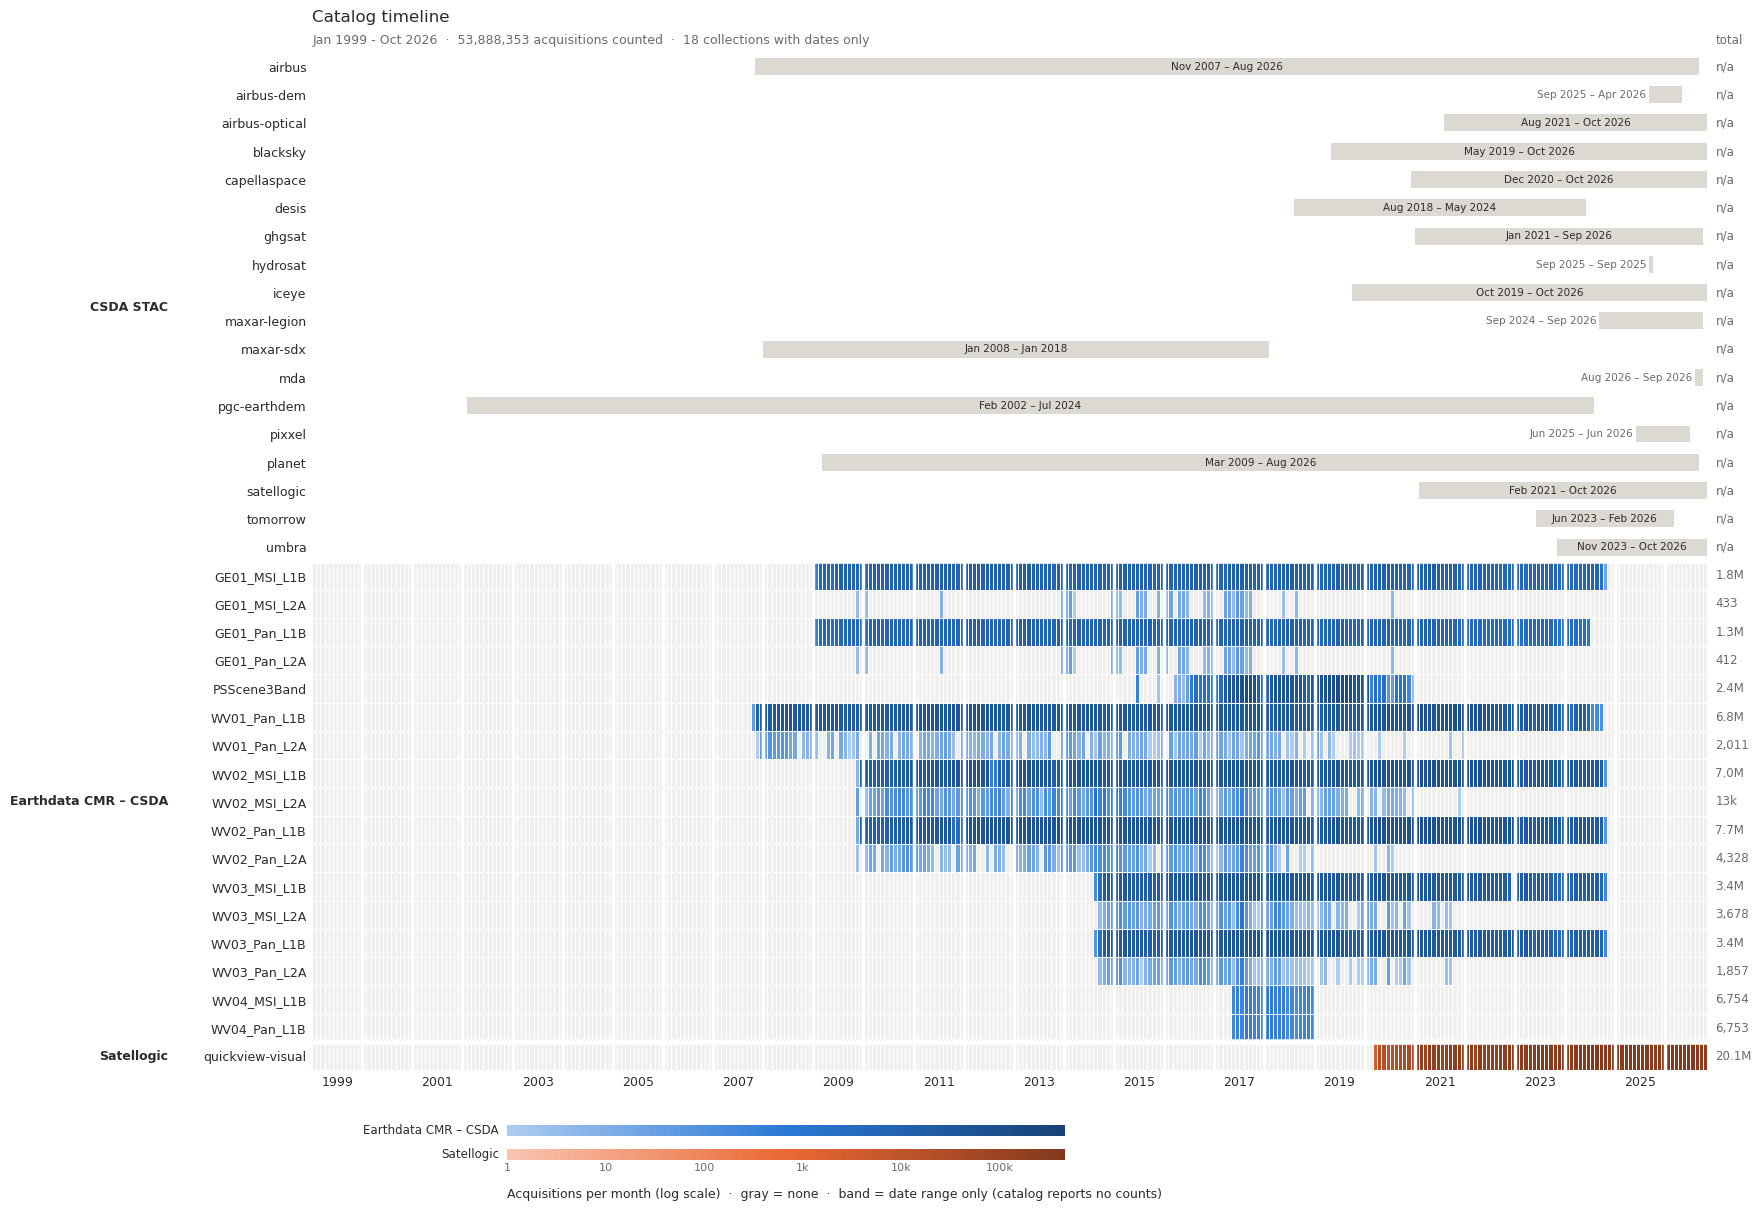

In [7]:
catalog_overview = multistac.overview(PROVIDERS, START, END)
catalog_months = multistac.overview_by_month(PROVIDERS, START, END)
multistac_plots.plot_month_heatmap(catalog_months, spans=catalog_overview, color_by='provider',
                                   start=START[:7], end=END[:7], title='Catalog timeline');
catalog_overview

## 2. Search the sites

In [8]:
res = multistac.search(sites, START, END, PROVIDERS, months=MONTHS,
                       cloud_cover_max=CLOUD_COVER_MAX, cache_dir=CACHE_DIR)
print(res)
res.log[res.log.status == 'failed']

searches: 100%|██████████| 76/76 [00:41<00:00,  1.82it/s]


SearchResult(7849 rows, 7849 unique items, 2 failed tasks)


,provider,collection,site_name,interval,status,count,server_filters,error,seconds
74,satellogic,quickview-visual,Casablanca,1999-01-01/2026-10-01,failed,0,,satellogic: HTTP 502 for POST https://api.sate...,31.8
75,satellogic,quickview-visual,Railroad Valley,1999-01-01/2026-10-01,failed,0,,satellogic: HTTP 502 for POST https://api.sate...,36.1


In [9]:
res.summary()

,provider,collection,processing_level,rows,items,sites,in_csda
0,csda,airbus-optical,ORT,54,54,1,54
1,csda,blacksky,NON-ORTHO,110,110,2,110
2,csda,blacksky,ORTHO,75,75,2,75
3,csda,desis,?,159,159,2,159
4,csda,maxar-legion,LV3D,4,4,1,4
5,csda,pgc-earthdem,?,11,11,1,11
6,csda,pixxel,L1C,38,38,1,38
7,csda,planet,?,3350,3350,2,3350
8,csda,satellogic,L1D,10,10,1,10
9,csda,satellogic,L1D_SR,3,3,1,3


## 3. What do we have, and where?

In [10]:
# Unique acquisitions per site and constellation
(res.gdf.groupby(['site_name', 'affiliation', 'constellation'])['id'].nunique()
    .unstack(['affiliation', 'constellation'], fill_value=0))

affiliation     BlackSky      Planet Satellogic Teledyne Vantor                    Airbus                     PGC  Pixxel   Planet Tomorrow.io
constellation   BlackSky PlanetScope    Aleph-1    DESIS GeoEye Legion WorldView Pleiades Pleiades Neo SPOT maxar Firefly RapidEye    Tomorrow
site_name                                                                                                                                     
Casablanca            92         138         13        2     14      4      2573        0            0    0     0       0        0           0
Railroad Valley       93        3206          0      157    252      0       500       12           36    6     1      38        6           2

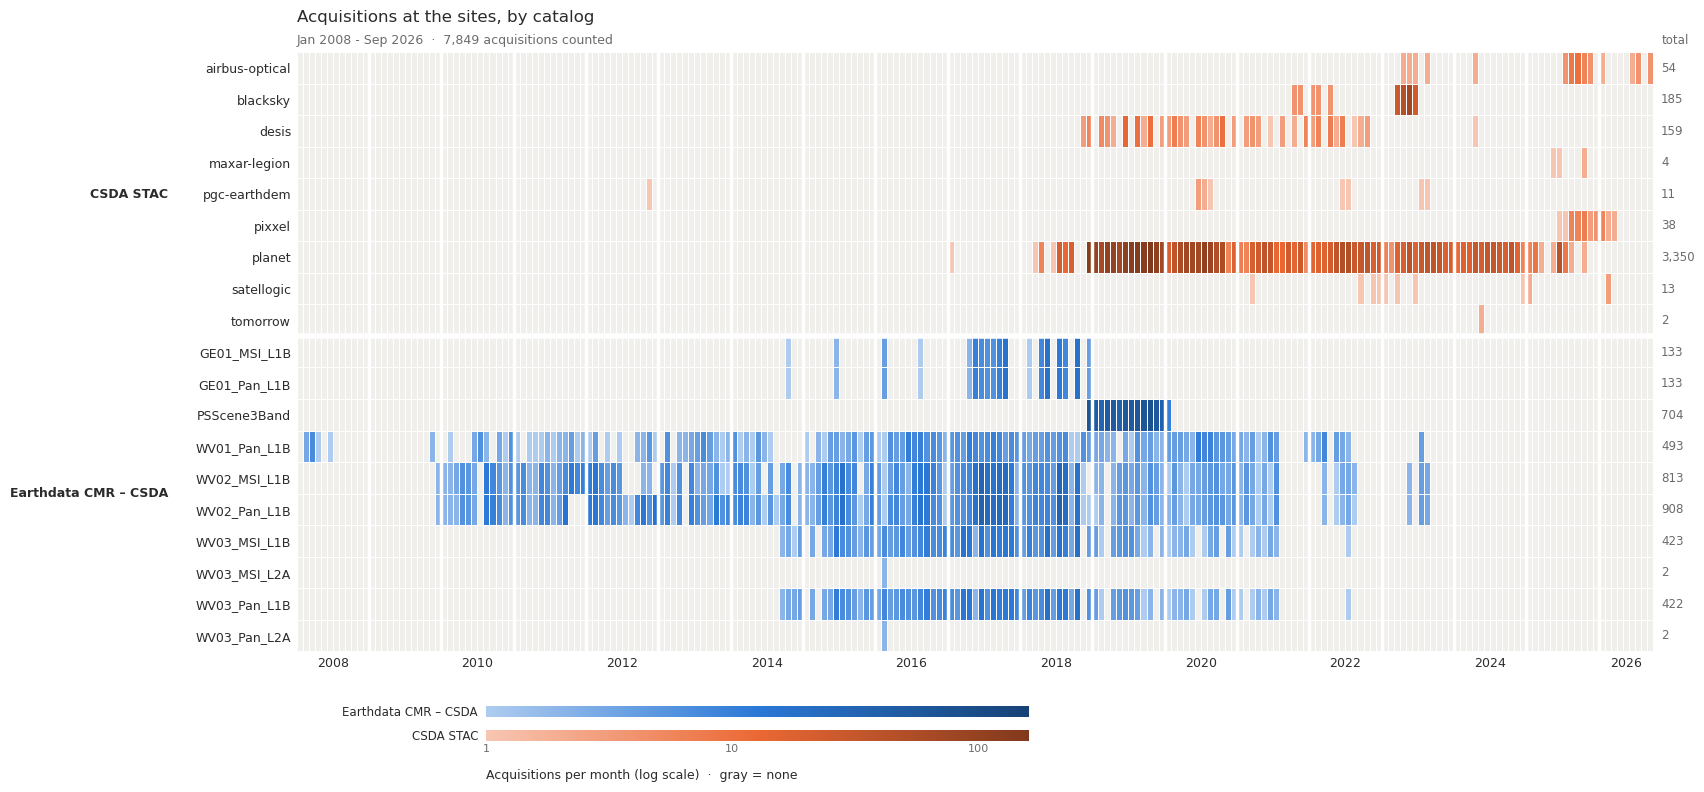

In [11]:
multistac_plots.plot_month_heatmap(res.by_month(['provider', 'collection']), color_by='provider',
                                   title='Acquisitions at the sites, by catalog');

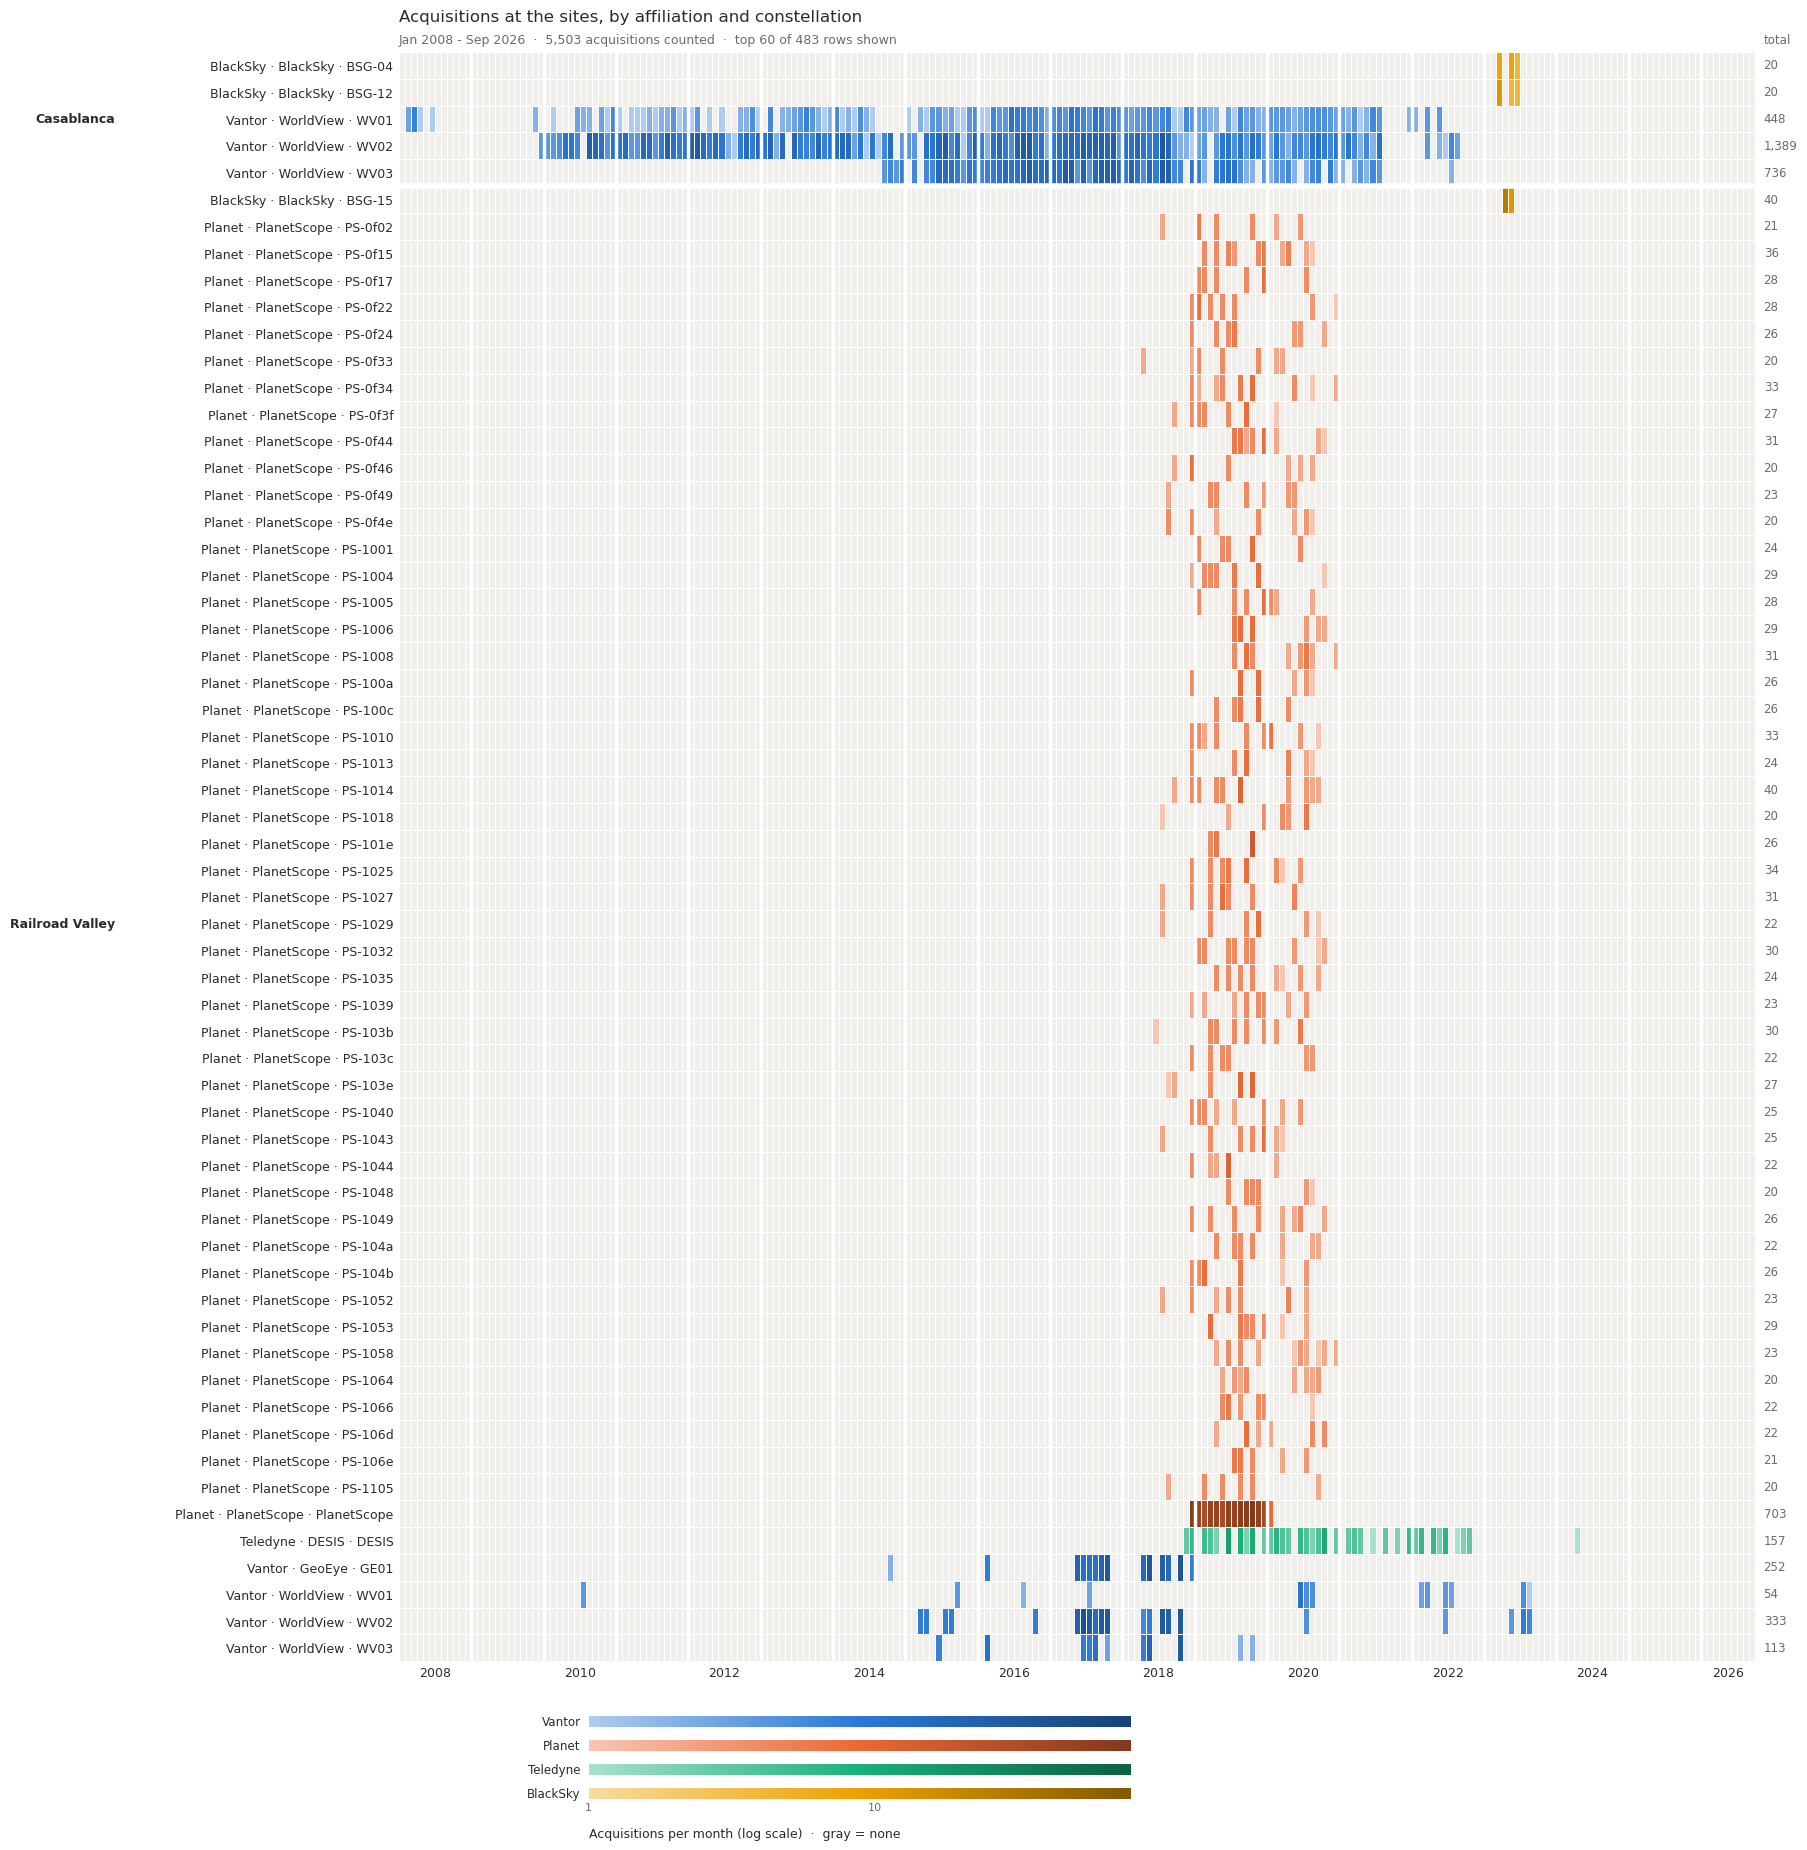

In [26]:
multistac_plots.plot_month_heatmap(res.by_month(['site_name','affiliation', 'constellation','sensor']), color_by='affiliation',
                                   title='Acquisitions at the sites, by affiliation and constellation');

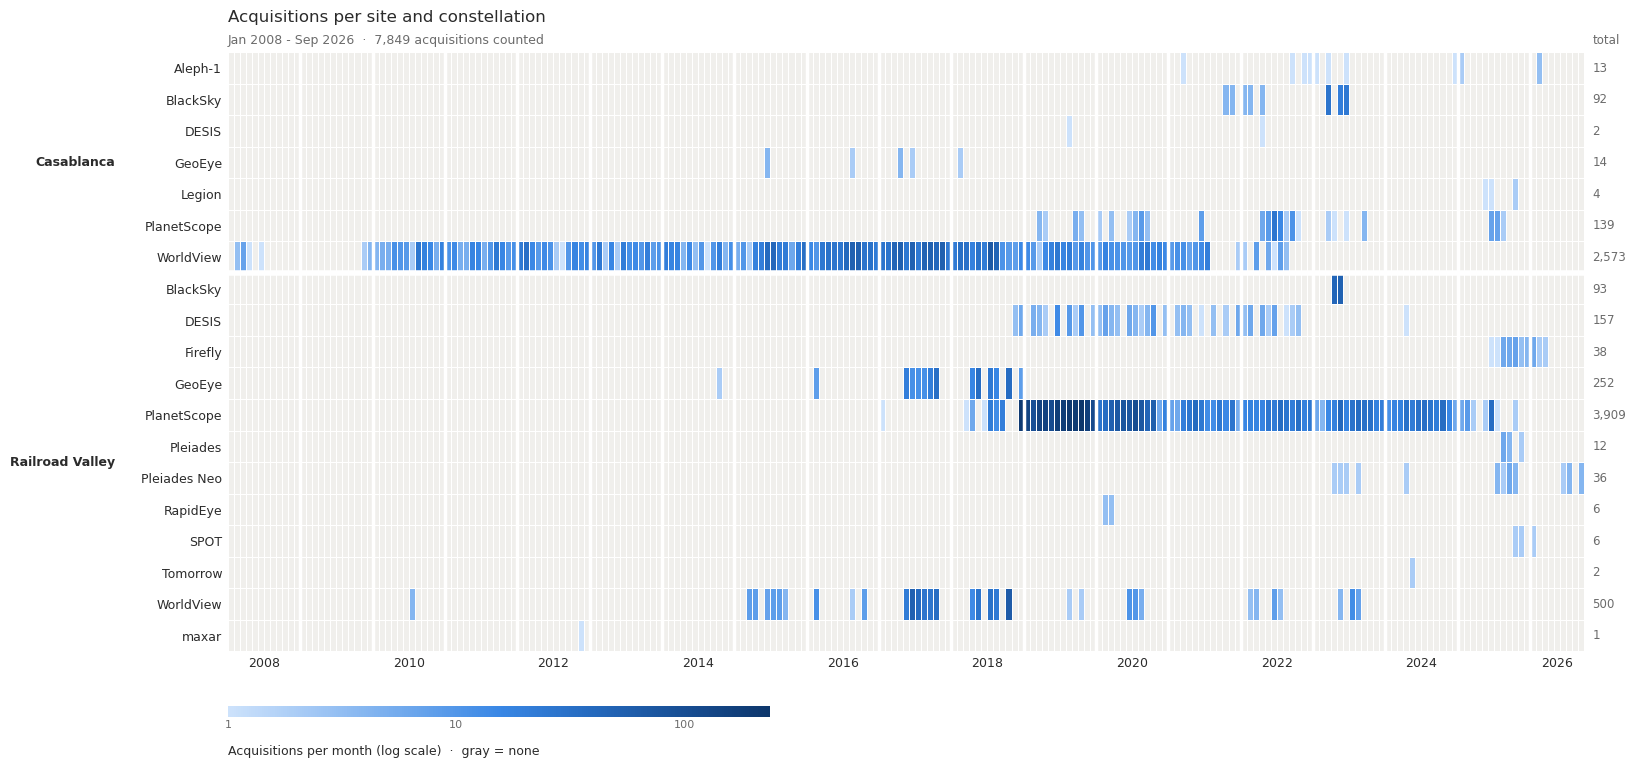

In [13]:
# Per site (rows = site · constellation); PlanetScope can dominate - drop it with a filter if needed
by_site = multistac.month_table(res.gdf, ['site_name', 'constellation'])
multistac_plots.plot_month_heatmap(by_site, max_rows=60, title='Acquisitions per site and constellation');

In [14]:
# Which vendor-archive scenes CSDA already holds (vendor API rows only)
vendor_rows = res.gdf[res.gdf.in_csda.notna() & ~res.gdf.provider.isin(['csda', 'csda-cmr'])]
vendor_rows.groupby(['site_name', 'provider', 'in_csda']).size().unstack(fill_value=0) if len(vendor_rows) else 'no vendor-archive rows'

'no vendor-archive rows'

## 4. Inherent variation: cloud, resolution, view and sun geometry

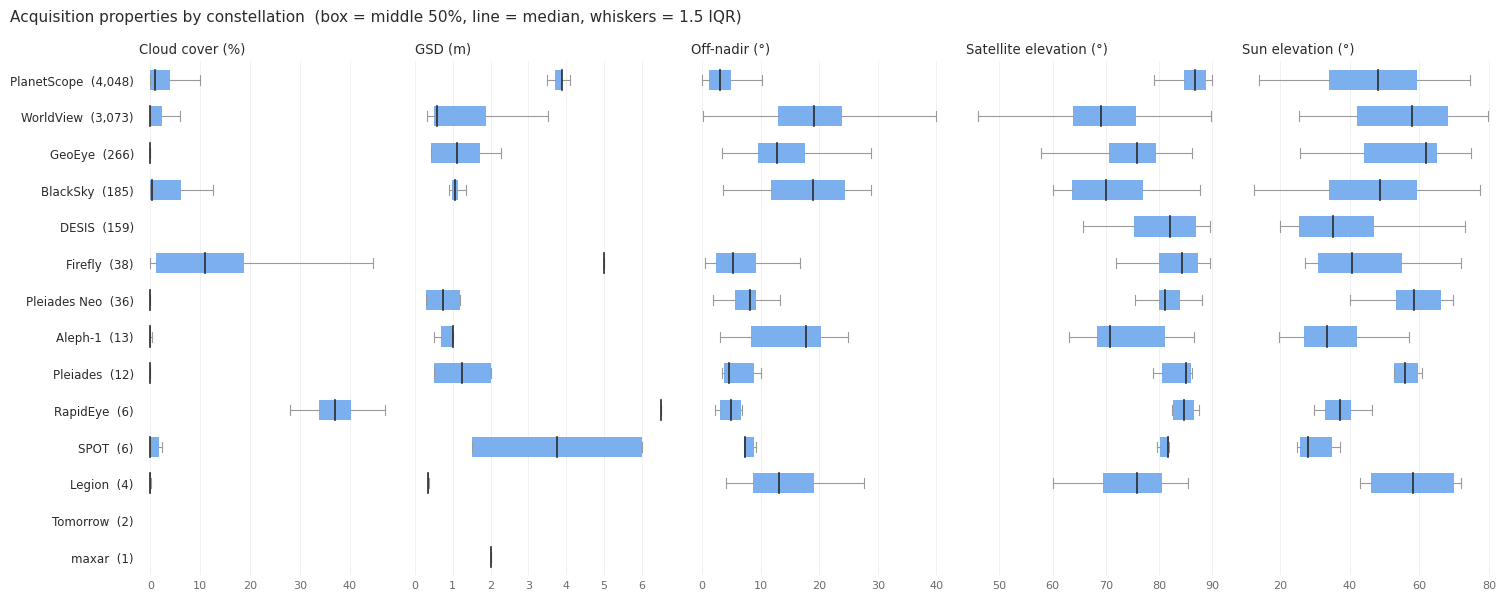

In [15]:
multistac_plots.plot_distributions(res.gdf, by='constellation');

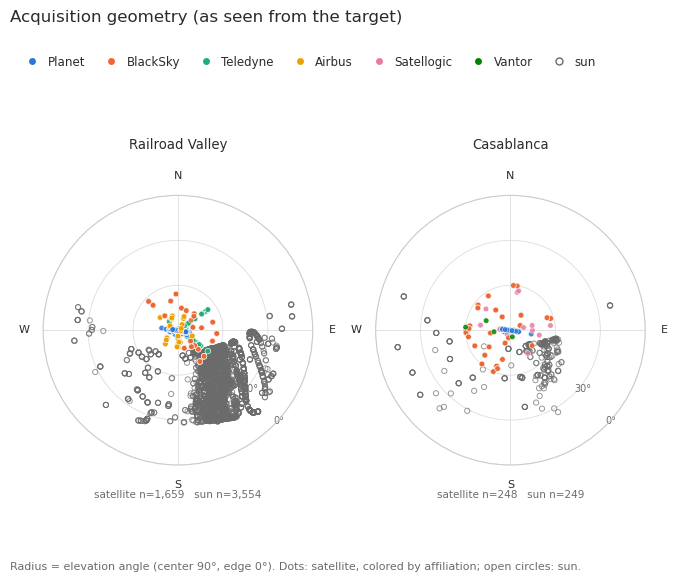

In [16]:
# Satellite and sun positions as seen from each site (satellite colored by constellation).
# CMR rows have no azimuths and are left out; sat_elevation_source says when elevation is estimated.
multistac_plots.plot_skyplot(res.gdf, facet_by='site_name', color_by='affiliation');

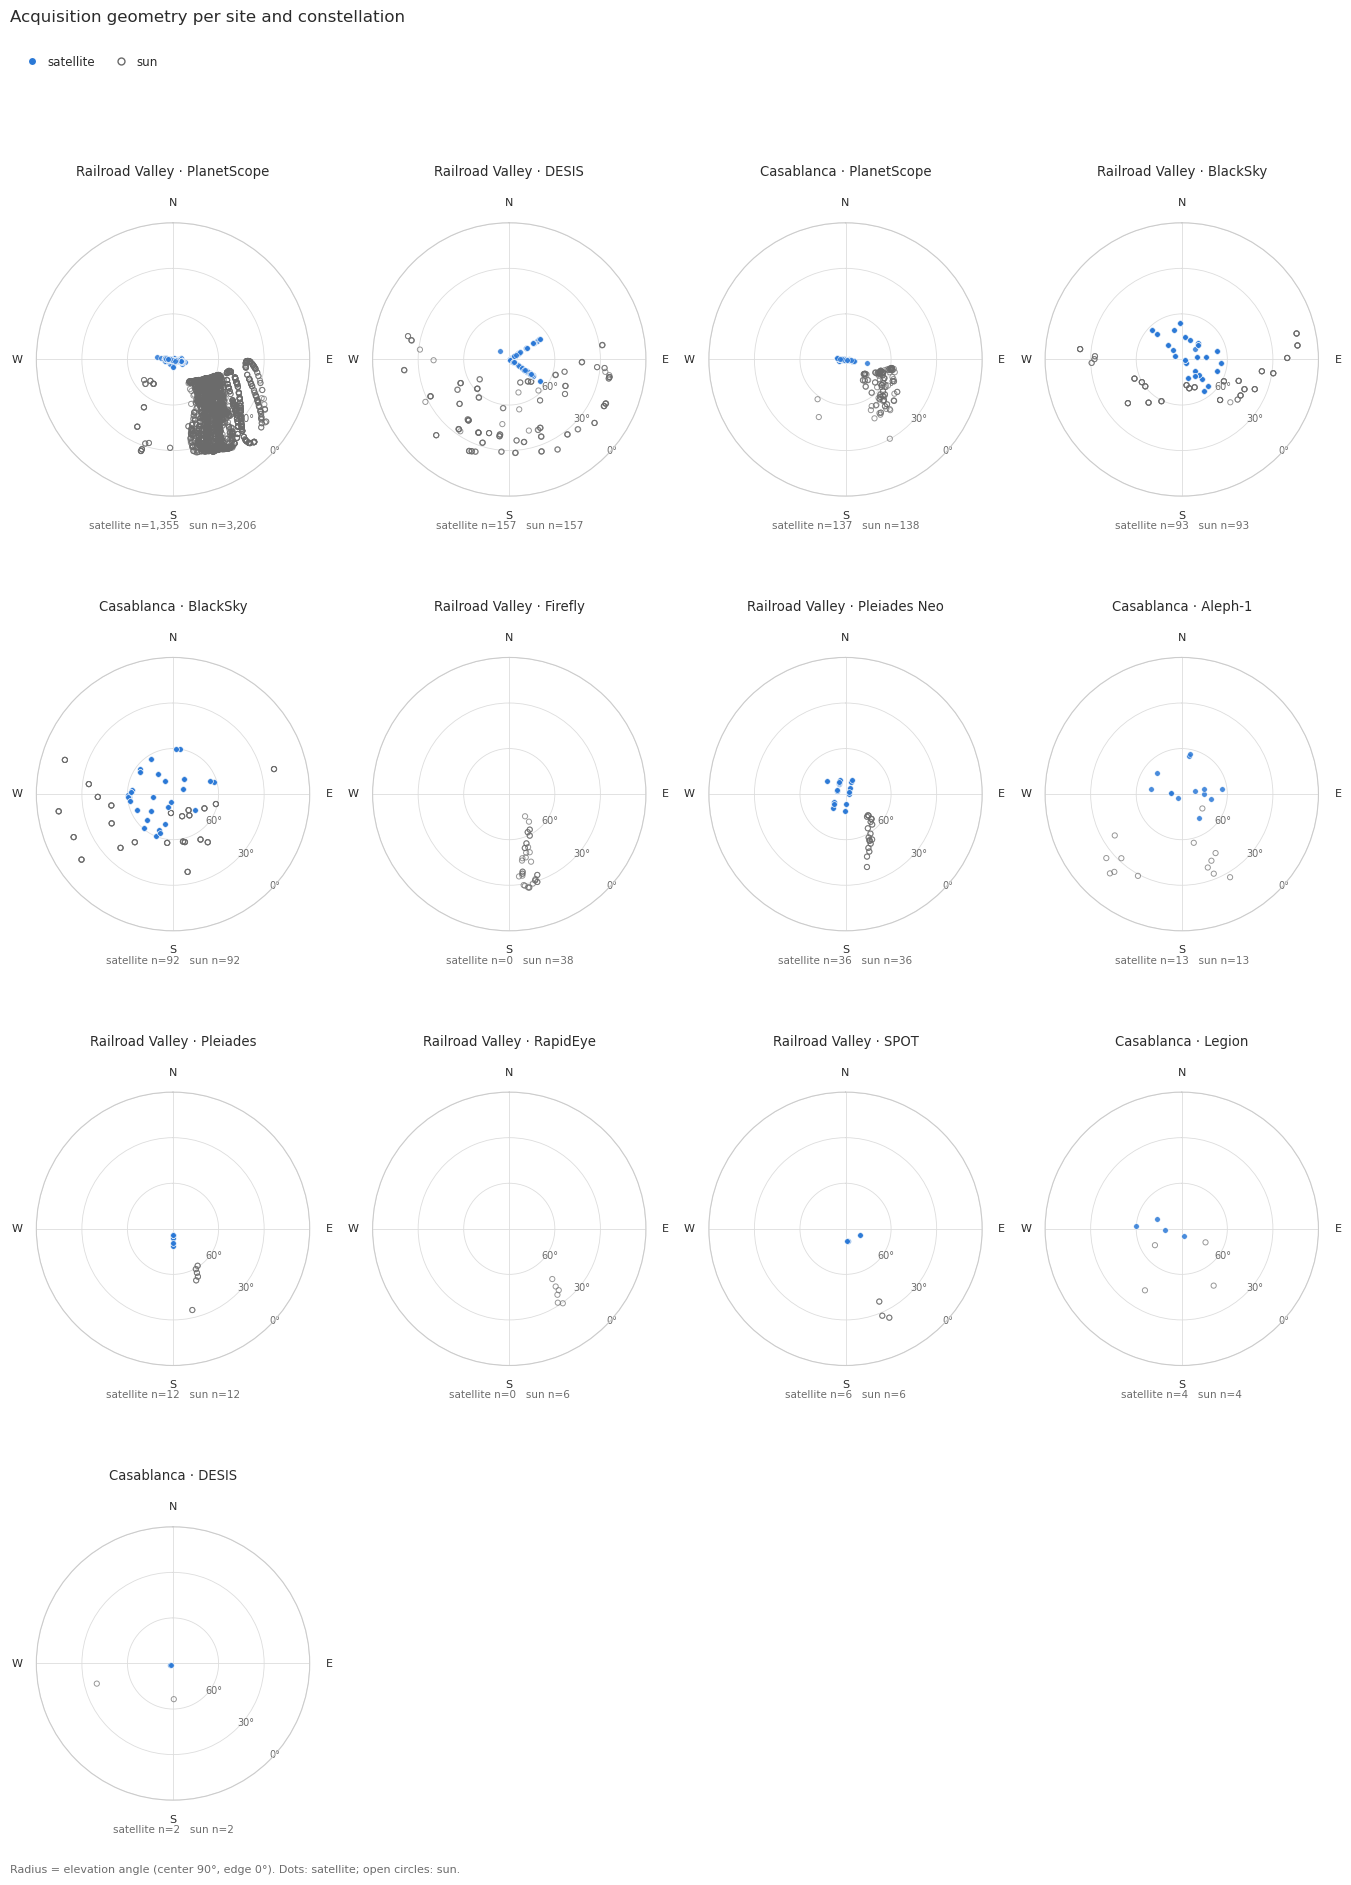

In [17]:
multistac_plots.plot_skyplot(res.gdf, facet_by=['site_name', 'constellation'], max_facets=16,
                             title='Acquisition geometry per site and constellation');

In [18]:
# Geometry coverage: how many rows have each angle, by collection
geom_cols = ['sun_azimuth', 'sun_elevation', 'sat_azimuth', 'sat_elevation']
res.gdf.groupby(['provider', 'collection'])[geom_cols].count()

sun_azimuth  sun_elevation  sat_azimuth  sat_elevation
provider collection                                                            
csda     airbus-optical           54             54           54             54
         blacksky                185            185          185            185
         desis                   159            159          159            159
         maxar-legion              4              4            4              4
         pgc-earthdem              0              0            0              0
         pixxel                   38             38            0             38
         planet                 3350           3350         1500           3233
         satellogic               13             13           13             13
         tomorrow                  0              0            0              0
csda-cmr GE01_MSI_L1B              0            133            0            133
         GE01_Pan_L1B              0            133            0            133
         PSScene3Band              0              0            0              0
         WV01_Pan_L1B              0            493            0            493
         WV02_MSI_L1B              0            813            0            813
         WV02_Pan_L1B              0            908            0            908
         WV03_MSI_L1B              0            423            0            423
         WV03_MSI_L2A              0              2            0              2
         WV03_Pan_L1B              0            422            0            422
         WV03_Pan_L2A              0              2            0              2

In [19]:
# Footprints at one site (interactive)
SITE = sites.site_name.iloc[0]
g = res.gdf[res.gdf.site_name == SITE]
cols = ['provider', 'constellation', 'sensor', 'datetime', 'cloud_cover', 'gsd', 'off_nadir', 'geometry']
g[cols].assign(datetime=g.datetime.astype(str)).explore(column='constellation', tooltip=cols[:-1])

## 5. Select and download

Downloads go through the CSDA download API (CSDA STAC rows) or Earthdata HTTPS (CMR rows), using
`[EarthData]` username/password from your credentials INI. Vendor-archive rows (e.g. Satellogic API)
are not downloadable here; use their CSDA copies (`in_csda`).

In [20]:
# Choose what you want: any pandas filter on res.gdf
selection = multistac.apply_filters(
    res.gdf[res.gdf.provider.isin(['csda', 'csda-cmr'])],
    cloud_cover_max=20,
    where=lambda g: g.sat_elevation.ge(60) | g.sat_elevation.isna(),
)
print(len(selection), 'acquisitions selected')
selection.groupby(['site_name', 'constellation']).size().unstack(fill_value=0)

6720 acquisitions selected


constellation,Aleph-1,BlackSky,Firefly,GeoEye,Legion,PlanetScope,Pleiades,Pleiades Neo,SPOT,WorldView
site_name,,,,,,,,,,
Casablanca,13,88,0,12,4,131,0,0,0,2182
Railroad Valley,0,85,30,224,0,3456,12,36,6,441


In [21]:
# Assets available for the selection (keys differ by collection)
assets = multistac_download.list_assets(res)
assets[assets.collection.isin(selection.collection.unique())]

,provider,collection,asset,roles,items,download
0,csda,airbus-optical,area-of-interest-mask,auxiliary,54,csda_api
1,csda,airbus-optical,auxiliary_0,auxiliary,54,csda_api
2,csda,airbus-optical,auxiliary_1,auxiliary,54,csda_api
3,csda,airbus-optical,auxiliary_2,auxiliary,30,csda_api
4,csda,airbus-optical,auxiliary_3,auxiliary,18,csda_api
...,...,...,...,...,...,...
1350,csda-cmr,WV03_Pan_L2A,cmr_json,metadata,2,earthdata
1351,csda-cmr,WV03_Pan_L2A,tar,data,2,earthdata
1352,csda-cmr,WV03_Pan_L2A,thumb_jpg,thumbnail,2,earthdata
1353,csda-cmr,WV03_Pan_L2A,tif,data,2,earthdata


In [22]:
ASSETS = ['metadata', 'xml-metadata', 'xml', 'IMD']   # asset keys to fetch; or use ROLES
ROLES = None                                            # e.g. ['metadata'] or ['data', 'metadata']

plan = multistac_download.download(res, OUT_DIR, assets=ASSETS if ROLES is None else None, roles=ROLES,
                                   ids=selection['id'], dry_run=True)
print(plan.status.value_counts().to_dict())
plan[['provider', 'collection', 'id', 'asset', 'method', 'path']].head(20)

{'planned': 3137}


,provider,collection,id,asset,method,path
0,csda-cmr,WV01_Pan_L1B,WV01_20080317112235_1020010002E61D00_08MAR1711...,xml,earthdata,/explore/nobackup/people/pmontesa/multistac/si...
1,csda-cmr,WV01_Pan_L1B,WV01_20080317112235_1020010002E61D00_08MAR1711...,xml,earthdata,/explore/nobackup/people/pmontesa/multistac/si...
2,csda-cmr,WV01_Pan_L1B,WV01_20080317112305_10200100022F3500_08MAR1711...,xml,earthdata,/explore/nobackup/people/pmontesa/multistac/si...
3,csda-cmr,WV01_Pan_L1B,WV01_20080317112305_10200100022F3500_08MAR1711...,xml,earthdata,/explore/nobackup/people/pmontesa/multistac/si...
4,csda-cmr,WV01_Pan_L1B,WV01_20080326111520_1020010002243000_08MAR2611...,xml,earthdata,/explore/nobackup/people/pmontesa/multistac/si...
5,csda-cmr,WV01_Pan_L1B,WV01_20080326111521_1020010002243000_08MAR2611...,xml,earthdata,/explore/nobackup/people/pmontesa/multistac/si...
6,csda-cmr,WV01_Pan_L1B,WV01_20080425112025_1020010002963100_08APR2511...,xml,earthdata,/explore/nobackup/people/pmontesa/multistac/si...
7,csda-cmr,WV02_Pan_L1B,WV02_20091206111940_1030010003A13300_09DEC0611...,xml,earthdata,/explore/nobackup/people/pmontesa/multistac/si...
8,csda-cmr,WV02_MSI_L1B,WV02_20091206111940_1030010003A13300_09DEC0611...,xml,earthdata,/explore/nobackup/people/pmontesa/multistac/si...
9,csda-cmr,WV02_Pan_L1B,WV02_20091206111941_1030010003A13300_09DEC0611...,xml,earthdata,/explore/nobackup/people/pmontesa/multistac/si...


In [ ]:
DO_DOWNLOAD = False   # set True to download the plan above
if DO_DOWNLOAD:
    manifest = multistac_download.download(res, OUT_DIR, assets=ASSETS if ROLES is None else None,
                                           roles=ROLES, ids=selection['id'])
    print(manifest.status.value_counts().to_dict())
    display(manifest[manifest.status == 'failed'][['provider', 'id', 'asset', 'error']].head())

## Save

In [ ]:
# Writes .gpkg, .csv, _items.geojson and _log.csv
# res.save(f'{OUT_DIR}/site_search_{START[:4]}_{END[:4]}')